# Ejercicio 4. Verificación del contador binario en una máquina de Turing

Este cuaderno acompaña al informe [`ejercicio-04.md`](ejercicio-04.md). Simula la misma tabla de transiciones, cuenta pasos de la máquina, comprueba el potencial y genera `ejercicio-04.png`. Las secciones siguen la numeración del informe.

Un paso lee, escribe, se mueve una celda a izquierda o derecha y cambia de estado. Se cuenta también el regreso de la cabeza al bit menos significativo. El costo no es el tiempo de ejecución de Python. Para reproducir el cuaderno hacen falta Python 3 y `matplotlib`.

In [1]:
import matplotlib.pyplot as plt

## 1. Formulación y modelo

La celda $-1$ contiene `#`, la celda 0 contiene el bit menos significativo y los pesos crecen hacia la derecha. Las celdas ausentes son blancos `_`. El contador comienza en 0. Cada incremento comienza y termina con la cabeza en 0.

Las siguientes funciones construyen y leen representaciones para las pruebas. El oráculo usa enteros Python; sus operaciones no se cuentan como pasos de la máquina.

In [2]:
def make_tape(value):
    assert value >= 0
    tape = {-1: '#'}
    tape.update(enumerate(format(value, 'b')[::-1]))
    return tape


def read_tape(tape):
    assert tape[-1] == '#'
    assert all(position >= -1 for position in tape)
    highest_position = max(tape)
    assert highest_position >= 0
    assert all(tape.get(i) in ('0', '1') for i in range(highest_position + 1))
    assert all(symbol in ('0', '1') for i, symbol in tape.items() if i >= 0)
    return sum(int(tape[i]) << i for i in range(highest_position + 1))


def potential(tape):
    return 2 * sum(symbol == '1' for symbol in tape.values())


def trailing_ones(value):
    # Oráculo independiente: cuenta el sufijo de unos en la escritura usual.
    bits = format(value, 'b')
    return len(bits) - len(bits.rstrip('1'))


assert make_tape(6) == {-1: '#', 0: '0', 1: '1', 2: '1'}
assert read_tape(make_tape(0)) == 0
assert potential(make_tape(0)) == 0

## 2. Máquina, correctitud y costo de un incremento

`A` propaga el acarreo, `R` regresa al marcador y `F` es el estado final. La tabla y el simulador siguientes son idénticos a los del informe. Solo se aplican transiciones locales; ninguna transición se mueve más de una celda.

In [3]:
TRANSITIONS = {
    ("A", "1"): ("A", "0", 1),
    ("A", "0"): ("R", "1", -1),
    ("A", "_"): ("R", "1", -1),
    ("R", "0"): ("R", "0", -1),
    ("R", "1"): ("R", "1", -1),
    ("R", "#"): ("F", "#", 1),
}


def increment(tape):
    head, state, steps = 0, "A", 0
    while state != "F":
        symbol = tape.get(head, "_")
        state, written, move = TRANSITIONS[state, symbol]
        tape[head] = written
        head += move
        steps += 1
    return steps, head

In [4]:
def trace_increment(value):
    tape = make_tape(value)
    head, state = 0, 'A'
    trace = []
    while state != 'F':
        symbol = tape.get(head, '_')
        new, written, move = TRANSITIONS[state, symbol]
        assert move in (-1, 1)
        trace.append((state, head, symbol, written, move, new))
        tape[head] = written
        head += move
        state = new
    direct = make_tape(value)
    steps, final_head = increment(direct)
    assert tape == direct and head == final_head == 0
    assert steps == len(trace)
    return tape, trace


tape, trace = trace_increment(7)
print('Traza del incremento de 7 a 8:')
print('paso  estado  celda  leído  escrito  movimiento  siguiente')
for i, (state, cell, read, written, move, new) in enumerate(trace, 1):
    direction = 'derecha' if move == 1 else 'izquierda'
    print(f'{i:4} {state:>7} {cell:6} {read:>6} {written:>8} {direction:>11} {new:>10}')
assert read_tape(tape) == 8
assert len(trace) == 8
steps, head = increment(tape)
assert read_tape(tape) == 9 and steps == 2 and head == 0
print('ok: 7 -> 8 cuesta 8 pasos; 8 -> 9 cuesta 2 pasos')

Traza del incremento de 7 a 8:
paso  estado  celda  leído  escrito  movimiento  siguiente
   1       A      0      1        0     derecha          A
   2       A      1      1        0     derecha          A
   3       A      2      1        0     derecha          A
   4       A      3      _        1   izquierda          R
   5       R      2      0        0   izquierda          R
   6       R      1      0        0   izquierda          R
   7       R      0      0        0   izquierda          R
   8       R     -1      #        #     derecha          F
ok: 7 -> 8 cuesta 8 pasos; 8 -> 9 cuesta 2 pasos


## 3. Potencial y cota amortizada

El potencial es $\Phi=2\operatorname{unos}(v)$. Si se borran $t$ unos y se crea uno, cambia en $2(1-t)$. El costo real es $2t+2$, así que $\widehat c=c+\Delta\Phi=4$.

Se simulan 4096 incrementos consecutivos desde 0. Después de cada uno se comprueban el valor, el marcador, la posición de la cabeza, el costo real, el potencial y el costo amortizado. Se conserva el mismo diccionario de cinta entre llamadas.

In [5]:
LIMIT = 4096
tape = make_tape(0)
records = []
cumulative_cost = 0
worst_cost = 0
for i in range(1, LIMIT + 1):
    before = potential(tape)
    t = trailing_ones(i - 1)
    actual_cost, head = increment(tape)
    after = potential(tape)
    assert read_tape(tape) == i
    assert head == 0
    assert actual_cost == 2 * t + 2
    assert after == 2 * i.bit_count()
    assert after - before == 2 * (1 - t)
    amortized_cost = actual_cost + after - before
    assert amortized_cost == 4
    cumulative_cost += actual_cost
    worst_cost = max(worst_cost, actual_cost)
    records.append(dict(i=i, t=t, actual_cost=actual_cost, phi=after,
                          amortized_cost=amortized_cost, total=cumulative_cost, worst_cost=worst_cost))

print(f'ok: {LIMIT} incrementos desde 0; valores y regreso de la cabeza correctos')
print('ok: costo real = 2t + 2; cambio de potencial = 2(1 − t)')
print('ok: costo amortizado = 4 en cada incremento')

ok: 4096 incrementos desde 0; valores y regreso de la cabeza correctos
ok: costo real = 2t + 2; cambio de potencial = 2(1 − t)
ok: costo amortizado = 4 en cada incremento


## 4. Peor caso individual y alcance de la cota

Se verifican $C(m)=4m-2\operatorname{unos}(m)$, $2m\le C(m)\le4m$ y la identidad del peor incremento para todos los prefijos de la secuencia. Para $m=0$, el costo total es cero. La tabla impresa coincide con la Tabla 1 del informe.

In [6]:
assert 4 * 0 - 2 * (0).bit_count() == 0
for r in records:
    m = r['i']
    assert r['total'] == 4 * m - 2 * m.bit_count()
    assert 2 * m <= r['total'] <= 4 * m
    assert 4 * m - r['total'] == r['phi']
    assert r['worst_cost'] == 2 * (m.bit_length() - 1) + 2

rows = [(r['i'] - 1, r['i'], r['t'], r['actual_cost'], r['phi'],
          r['amortized_cost'], r['total']) for r in records[:8]]
assert rows == [
    (0, 1, 0, 2, 2, 4, 2), (1, 2, 1, 4, 2, 4, 6),
    (2, 3, 0, 2, 4, 4, 8), (3, 4, 2, 6, 2, 4, 14),
    (4, 5, 0, 2, 4, 4, 16), (5, 6, 1, 4, 4, 4, 20),
    (6, 7, 0, 2, 6, 4, 22), (7, 8, 3, 8, 2, 4, 30),
]
print('anterior  nuevo   t  real  potencial  amortizado  acumulado')
for previous, new, t, actual_cost, phi, amortized_cost, total in rows:
    print(f'{previous:8} {new:6} {t:3} {actual_cost:5} {phi:10} {amortized_cost:11} {total:10}')
print('ok: total, potencial final y peor caso en todos los prefijos')
print(f"m={LIMIT}: total={records[-1]['total']}, peor incremento={records[-1]['worst_cost']}")

anterior  nuevo   t  real  potencial  amortizado  acumulado
       0      1   0     2          2           4          2
       1      2   1     4          2           4          6
       2      3   0     2          4           4          8
       3      4   2     6          2           4         14
       4      5   0     2          4           4         16
       5      6   1     4          4           4         20
       6      7   0     2          6           4         22
       7      8   3     8          2           4         30
ok: total, potencial final y peor caso en todos los prefijos
m=4096: total=16382, peor incremento=26


## 5. Casos de prueba

Para comprobar el papel del potencial inicial se ejecutan 33 incrementos desde cada valor $a$ entre 0 y 255. En cada prefijo se verifica

$$C_a(m)=4m+2\operatorname{unos}(a)-2\operatorname{unos}(a+m).$$

También se comprueba un acarreo que atraviesa todos los bits para cada longitud de 1 a 32. Estas pruebas verifican la implementación; la demostración por potencial cubre cualquier longitud.

In [7]:
additional_increments = 0
for a in range(256):
    tape = make_tape(a)
    initial = potential(tape)
    total = 0
    assert initial == 2 * a.bit_count()
    assert total == 4 * 0 + initial - potential(tape)
    for m in range(1, 34):
        before = potential(tape)
        t = trailing_ones(a + m - 1)
        actual_cost, head = increment(tape)
        after = potential(tape)
        assert read_tape(tape) == a + m and head == 0
        assert actual_cost == 2 * t + 2
        assert after == 2 * (a + m).bit_count()
        assert actual_cost + after - before == 4
        total += actual_cost
        assert total == 4 * m + 2 * a.bit_count() - 2 * (a + m).bit_count()
        assert total <= 4 * m + initial
        additional_increments += 1

assert additional_increments == 8448
print(f'ok: {additional_increments} incrementos adicionales desde estados iniciales de 0 a 255')

for k in range(1, 33):
    tape = make_tape(2**k - 1)
    assert potential(tape) == 2 * k
    actual_cost, head = increment(tape)
    assert read_tape(tape) == 2**k and head == 0
    assert actual_cost == 2 * k + 2
    assert potential(tape) == 2
print('ok: acarreos completos de 1 a 32 bits, incluida la extensión sobre blanco')

ok: 8448 incrementos adicionales desde estados iniciales de 0 a 255
ok: acarreos completos de 1 a 32 bits, incluida la extensión sobre blanco


## Figura 1

A la izquierda se muestran los costos reales y el amortizado de los primeros 64 incrementos. A la derecha, el total y su cota $4m$. La diferencia $4m-C(m)$ es exactamente el potencial final. Se guarda la imagen como `ejercicio-04.png`, que es la que incluye el informe.

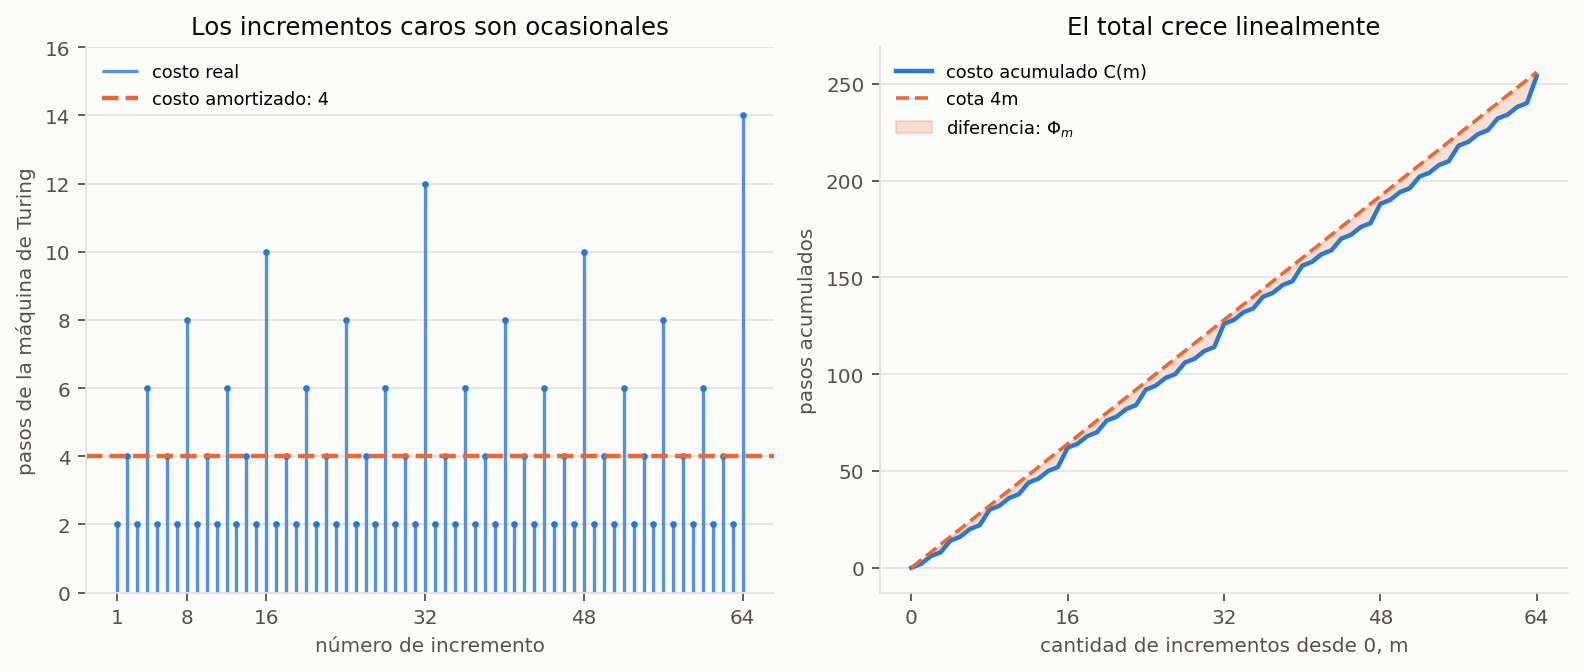

In [8]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink, grid_color, background = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
fig, (ax_c, ax_t) = plt.subplots(1, 2, figsize=(10, 4.3), dpi=160)
fig.patch.set_facecolor(background)
sample = records[:64]
indices = [r['i'] for r in sample]
actual_costs = [r['actual_cost'] for r in sample]
ax_c.vlines(indices, 0, actual_costs, color=blue, lw=1.5, alpha=0.8, label='costo real')
ax_c.plot(indices, actual_costs, '.', color=blue, ms=4)
ax_c.axhline(4, color=orange, lw=2, ls='--', label='costo amortizado: 4')
ax_c.set_title('Los incrementos caros son ocasionales', color=ink, fontsize=11)
ax_c.set_xlabel('número de incremento', color=secondary_ink, fontsize=9)
ax_c.set_ylabel('pasos de la máquina de Turing', color=secondary_ink, fontsize=9)
ax_c.set_ylim(0, 16)
ax_c.set_yticks(range(0, 17, 2))
ax_c.set_xticks([1, 8, 16, 32, 48, 64])
ax_c.legend(frameon=False, fontsize=8, loc='upper left')

ms = [0] + indices
cumulative_costs = [0] + [r['total'] for r in sample]
upper_bound = [4 * m for m in ms]
ax_t.plot(ms, cumulative_costs, color=blue, lw=2, label='costo acumulado C(m)')
ax_t.plot(ms, upper_bound, color=orange, lw=1.6, ls='--', label='cota 4m')
ax_t.fill_between(ms, cumulative_costs, upper_bound, color=orange, alpha=0.2,
                  label=r'diferencia: $\Phi_m$')
ax_t.set_title('El total crece linealmente', color=ink, fontsize=11)
ax_t.set_xlabel('cantidad de incrementos desde 0, m', color=secondary_ink, fontsize=9)
ax_t.set_ylabel('pasos acumulados', color=secondary_ink, fontsize=9)
ax_t.set_xticks([0, 16, 32, 48, 64])
ax_t.legend(frameon=False, fontsize=8, loc='upper left')

for ax in [ax_c, ax_t]:
    ax.set_facecolor(background)
    ax.grid(axis='y', color=grid_color, lw=0.8)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(grid_color)
    ax.tick_params(colors=secondary_ink, labelsize=9)
fig.tight_layout()
fig.savefig('ejercicio-04.png', facecolor=background)
plt.show()

## 6. Conclusiones

El potencial $2\operatorname{unos}(v)$ paga la ida y la vuelta sobre cada uno borrado. Cada incremento tiene costo amortizado 4, el potencial inicial es cero y el final no es negativo. Por eso el costo total de $m$ incrementos desde 0 es $\Theta(m)$, aunque el peor incremento de esa secuencia pueda costar $\Theta(\log m)$.

In [9]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Incrementos consecutivos desde 0: {LIMIT}')
print(f'Incrementos desde estados iniciales arbitrarios: {additional_increments}')
print('Acarreos completos adicionales: 32')
print('Figura guardada en ejercicio-04.png')

Todas las comprobaciones finalizaron correctamente.
Incrementos consecutivos desde 0: 4096
Incrementos desde estados iniciales arbitrarios: 8448
Acarreos completos adicionales: 32
Figura guardada en ejercicio-04.png
